In [1]:
# CELL 1: Imports

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt

df = pd.read_csv(
    "../data/processed/logistics_features.csv"
)

print("Dataset loaded:", df.shape)

Dataset loaded: (180519, 44)


In [2]:
# CELL 2: Select target and features

target = "late_delivery_risk"

# Exclude actual shipping duration and delivery status
# to reduce direct target leakage.

numeric_features = [
    "days_for_shipment_scheduled",
    "benefit_per_order",
    "sales_per_customer",
    "order_item_discount",
    "order_item_discount_rate",
    "order_item_product_price",
    "order_item_profit_ratio",
    "order_item_quantity",
    "sales",
    "order_item_total",
    "product_price"
]

categorical_features = [
    "shipping_mode",
    "market",
    "order_region",
    "customer_segment",
    "category_name",
    "department_name"
]

features = numeric_features + categorical_features

X = df[features].copy()
y = df[target].copy()

print("Features:", X.shape)
print("Target distribution:")
print(y.value_counts())

Features: (180519, 17)
Target distribution:
late_delivery_risk
1    98977
0    81542
Name: count, dtype: int64


In [3]:
# CELL 3: Preprocessing pipeline

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_transformer, numeric_features),
        ("categorical", categorical_transformer, categorical_features)
    ]
)

In [4]:
# CELL 4: Train-test split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 144415
Testing records: 36104


In [5]:
# CELL 5: Train Random Forest

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        max_depth=15,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])

model.fit(X_train, y_train)

print("Model training completed!")

Model training completed!


In [6]:
# CELL 6: Model evaluation

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Model Accuracy: 69.71 %

Classification Report:
              precision    recall  f1-score   support

           0       0.62      0.88      0.72     16308
           1       0.85      0.55      0.66     19796

    accuracy                           0.70     36104
   macro avg       0.73      0.71      0.69     36104
weighted avg       0.74      0.70      0.69     36104



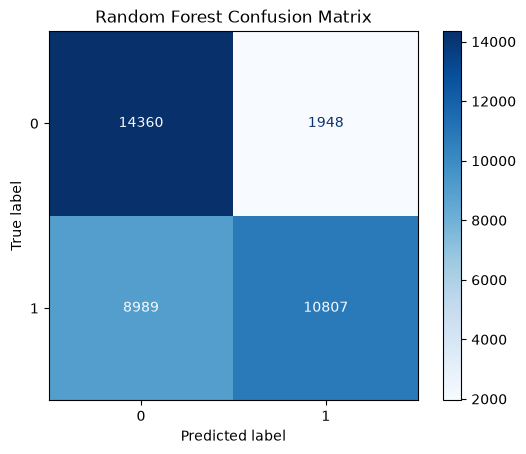

In [7]:
# CELL 7: Confusion matrix

cm = confusion_matrix(y_test, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm
)

display.plot(cmap="Blues")

plt.title("Random Forest Confusion Matrix")
plt.show()

In [8]:
# CELL 8: Save trained model

import joblib
from pathlib import Path

MODEL_DIR = Path("../models")
MODEL_DIR.mkdir(parents=True, exist_ok=True)

joblib.dump(
    model,
    MODEL_DIR / "late_delivery_risk_model.pkl"
)

print("Model saved successfully!")

Model saved successfully!
